# **Student Academic Performance Prediction**

**Assessment:** Verveox Technologies — AI/ML Trainee Practical Assessment  
**Objective:** Build an end-to-end binary classification pipeline to predict whether a student will **Pass** or **Fail** based on academic and study-related indicators, helping educators identify students who may need additional academic support.

# **1: Data Exploration and Preprocessing**

### *1.1 Import Libraries and Load Dataset*
We use the **Student Performance Factors** public dataset (6,607 records) and map its columns to the required problem fields:
- `Hours_Studied` $\rightarrow$ `study_hours` (Weekly study hours; numeric)
- `Attendance` $\rightarrow$ `attendance` (Attendance percentage: 0–100%)
- `Previous_Scores` $\rightarrow$ `previous_score` (Previous examination score: 0–100 scale)
- `Tutoring_Sessions` $\rightarrow$ `assignments_completed` (Count of extra academic practice/tutoring sessions completed)
- `Sleep_Hours` $\rightarrow$ `sleep_hours` (Average sleep hours per day)
- `Exam_Score` $\rightarrow$ Used to derive the binary target `final_result` (`Pass` if score $\ge 65$, else `Fail`), and subsequently dropped to prevent data leakage.

In [28]:
import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

In [ ]:
# Load the raw dataset from the data directory (supports local workspace and Colab)
possible_data_paths = [
    "data/StudentPerformanceFactors.csv",
    "../data/StudentPerformanceFactors.csv",
    "/content/StudentPerformanceFactors.csv",
    "StudentPerformanceFactors.csv",
]
data_set = next((p for p in possible_data_paths if os.path.exists(p)), None)

if data_set is None:
    raise FileNotFoundError(
        "Could not find 'StudentPerformanceFactors.csv'. Please ensure it exists in 'data/' or '/content/'."
    )

df = pd.read_csv(data_set)
df

In [30]:
# Map dataset fields to the assessment's required schema
column_mapping = {
    "Hours_Studied": "study_hours",
    "Attendance": "attendance",
    "Previous_Scores": "previous_score",
    "Tutoring_Sessions": "assignments_completed",
    "Sleep_Hours": "sleep_hours",
    "Exam_Score": "Exam_Score",
}

# Slice the relevant columns and rename them
df = df[list(column_mapping.keys())].rename(columns=column_mapping)
print("Dataset loaded and mapped successfully!")

Dataset loaded and mapped successfully!


## **1.2: Display First 5 and Last 5 Rows**

Displaying the first 5 and last 5 records to verify that the data loaded properly and matches expected formats.

In [31]:
print("--- FIRST 5 ROWS ---")
display(df.head(5))

print("\n--- LAST 5 ROWS ---")
display(df.tail(5))

--- FIRST 5 ROWS ---


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
0,23,84,73,0,7,67
1,19,64,59,2,8,61
2,24,98,91,2,7,74
3,29,89,98,1,8,71
4,19,92,65,3,6,70



--- LAST 5 ROWS ---


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
6602,25,69,76,1,7,68
6603,23,76,81,3,8,69
6604,20,90,65,3,6,68
6605,10,86,91,2,6,68
6606,15,67,94,0,9,64


## **1.3: Dataset Dimensions, Data Types & Summary Statistics**

Checking the number of rows and columns, verifying data types, and reviewing descriptive statistics (count, mean, standard deviation, min, quartiles, and max).

In [32]:
print(f"Dataset Dimensions: {df.shape[0]} rows and {df.shape[1]} columns\n")
print("Column Names:", df.columns.tolist())

print("\n--- DATA TYPES ---")
print(df.dtypes)

print("\n--- SUMMARY STATISTICS ---")
display(df.describe().round(2))

Dataset Dimensions: 6607 rows and 6 columns

Column Names: ['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'sleep_hours', 'Exam_Score']

--- DATA TYPES ---
study_hours              int64
attendance               int64
previous_score           int64
assignments_completed    int64
sleep_hours              int64
Exam_Score               int64
dtype: object

--- SUMMARY STATISTICS ---


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
count,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00
mean,19.98,79.98,75.07,1.49,7.03,67.24
std,5.99,11.55,14.40,1.23,1.47,3.89
min,1.00,60.00,50.00,0.00,4.00,55.00
25%,16.00,70.00,63.00,1.00,6.00,65.00
50%,20.00,80.00,75.00,1.00,7.00,67.00
75%,24.00,90.00,88.00,2.00,8.00,69.00
max,44.00,100.00,100.00,8.00,10.00,101.00


## **1.4: Check Missing Values, Duplicates, and Invalid/Suspicious Values**

We inspect the dataset for:
1. **Missing values (`NaN` / `null`)** in any of the selected columns.
2. **Duplicate rows** across the selected feature and score columns.
3. **Invalid or suspicious values**, including:
   - `attendance` outside the valid `0–100` percentage range.
   - `previous_score` or `final_result` outside the `0–100` mark scale.
   - Negative counts in `assignments_completed` (`< 0`).
   - Implausible `sleep_hours` (`<= 0` or `> 24` hours/day) or `study_hours` (`<= 0` or `> 168` hours/week).

In [33]:
print("--- 1. MISSING VALUES PER COLUMN ---")
print(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print(f"\n--- 2. DUPLICATE ROWS COUNT: {duplicate_count} ---")
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(by="study_hours"))

print("\n--- 3. INVALID / SUSPICIOUS VALUES CHECK ---")
invalid_checks = {
    "study_hours (<= 0 or > 168 hrs/week)": len(
        df[(df["study_hours"] <= 0) | (df["study_hours"] > 168)]
    ),
    "attendance (< 0 or > 100%)": len(
        df[(df["attendance"] < 0) | (df["attendance"] > 100)]
    ),
    "previous_score (< 0 or > 100)": len(
        df[(df["previous_score"] < 0) | (df["previous_score"] > 100)]
    ),
    "assignments_completed (< 0)": len(df[df["assignments_completed"] < 0]),
    "sleep_hours (<= 0 or > 24 hrs/day)": len(
        df[(df["sleep_hours"] <= 0) | (df["sleep_hours"] > 24)]
    ),
    "Exam_Score (< 0 or > 100)": len(
        df[(df["Exam_Score"] < 0) | (df["Exam_Score"] > 100)]
    ),
}

for check_name, count in invalid_checks.items():
    print(f"{check_name}: {count}")

# Display the specific invalid row(s) where Exam_Score > 100
print("\nRow(s) with invalid Exam_Score (> 100):")
display(df[df["Exam_Score"] > 100])

--- 1. MISSING VALUES PER COLUMN ---
study_hours              0
attendance               0
previous_score           0
assignments_completed    0
sleep_hours              0
Exam_Score               0
dtype: int64

--- 2. DUPLICATE ROWS COUNT: 6 ---


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
2665,12,74,66,1,8,62
2377,12,74,66,1,8,62
5925,15,89,55,1,6,66
6368,15,89,55,1,6,66
292,16,67,98,0,8,63
1050,16,67,98,0,8,63
3254,22,71,65,1,7,64
50,22,71,65,1,7,64
3972,22,85,79,1,4,68
3940,22,85,79,1,4,68



--- 3. INVALID / SUSPICIOUS VALUES CHECK ---
study_hours (<= 0 or > 168 hrs/week): 0
attendance (< 0 or > 100%): 0
previous_score (< 0 or > 100): 0
assignments_completed (< 0): 0
sleep_hours (<= 0 or > 24 hrs/day): 0
Exam_Score (< 0 or > 100): 1

Row(s) with invalid Exam_Score (> 100):


,study_hours,attendance,previous_score,assignments_completed,sleep_hours,Exam_Score
1525,27,98,93,5,6,101


## **1.5: Handle Anomalies, Create Target Label & Separate $X$ and $y$**

#### Justification of Preprocessing Decisions:
1. **Invalid Value Handling (`Exam_Score > 100`):**  
   Inspection revealed **1 record** (Index `1525`) with `Exam_Score = 101`, which exceeds the maximum possible score of 100. Because this is a clear data entry anomaly affecting the target variable, we remove this single record (`6,607` $\rightarrow$ `6,606` rows).
2. **Duplicate Rows Handling:**  
   There are **6 exact duplicate rows** across the 6 selected columns. In tabular classification, keeping identical feature-target rows can bias the train/test split (if one copy lands in train and the exact duplicate lands in test, it causes optimistic evaluation leakage). Therefore, we drop the 6 duplicate rows (`6,606` $\rightarrow$ `6,600` rows).
3. **Missing Values Handling:**  
   The 6 selected numeric columns contain **0 missing values**. (However, to ensure a production-ready pipeline in Task 3, we can still include a `SimpleImputer(strategy='median')` inside our Scikit-learn Pipeline to handle any unseen missing values safely).
4. **Target Label Derivation (`final_result`) & Leakage Prevention:**  
   Since `Exam_Score` in this dataset ranges from `55` to `100` (mean `67.23`, 25th percentile `65.0`), using a benchmark of **65 marks** represents a realistic school competency threshold (`Exam_Score >= 65` $\rightarrow$ `Pass`, `< 65` $\rightarrow$ `Fail`). Immediately after creating `final_result`, we drop `Exam_Score` so it is never used as an input feature.

In [34]:
# 1. Remove invalid Exam_Score (> 100)
df_cleaned = df[df["Exam_Score"] <= 100].copy()
print(f"Shape after removing invalid Exam_Score (>100): {df_cleaned.shape}")

# 2. Remove exact duplicate rows
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing 6 duplicate rows: {df_cleaned.shape}")

# 3. Create binary target column 'final_result' (Pass if Exam_Score >= 65 else Fail)
df_cleaned["final_result"] = np.where(
    df_cleaned["Exam_Score"] >= 65, "Pass", "Fail"
)

# 4. Drop 'Exam_Score' immediately to prevent target leakage
df_cleaned = df_cleaned.drop(columns=["Exam_Score"])

# Save cleaned dataset for reproducibility
# Save cleaned dataset for reproducibility (supports local workspace and Colab)
cleaned_dir = "data" if os.path.exists("data") else ("../data" if os.path.exists("../data") else "/content")
os.makedirs(cleaned_dir, exist_ok=True)
cleaned_path = os.path.join(cleaned_dir, "cleaned_StudentPerformanceFactors.csv")
df_cleaned.to_csv(cleaned_path, index=False)
print(f"Cleaned dataset saved to '{cleaned_path}'\n")

# 5. Separate Input Features (X) and Target Label (y)
X = df_cleaned.drop(columns=["final_result"])
y = df_cleaned["final_result"]

# 6. Confirm separation and verify target is NOT in X
print("Input Features (X) shape:", X.shape)
print("Input Feature columns:", X.columns.tolist())
assert (
    "final_result" not in X.columns and "Exam_Score" not in X.columns
), "Error: Target leakage detected!"
print(
    "Verification Passed: Target column is strictly separated from input features.\n"
)

print("Target (y) Class Distribution:")
target_counts = y.value_counts()
target_pct = (y.value_counts(normalize=True) * 100).round(2)
summary_target = pd.DataFrame(
    {"Count": target_counts, "Percentage (%)": target_pct}
)
display(summary_target)

Shape after removing invalid Exam_Score (>100): (6606, 6)
Shape after removing 6 duplicate rows: (6600, 6)
Cleaned dataset saved to '../data/cleaned_student_performance_cleaned.csv'

Input Features (X) shape: (6600, 5)
Input Feature columns: ['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'sleep_hours']
Verification Passed: Target column is strictly separated from input features.

Target (y) Class Distribution:


,Count,Percentage (%)
final_result,,
Pass,5151,78.05
Fail,1449,21.95


In [37]:
df_cleaned.head()

,study_hours,attendance,previous_score,assignments_completed,sleep_hours,final_result
0,23,84,73,0,7,Pass
1,19,64,59,2,8,Fail
2,24,98,91,2,7,Pass
3,29,89,98,1,8,Pass
4,19,92,65,3,6,Pass


## **1.6: Brief Data-Quality Summary**

- **Initial Records:** 6,607 rows, 6 mapped columns (`study_hours`, `attendance`, `previous_score`, `assignments_completed`, `sleep_hours`, `Exam_Score`).
- **Missing Values:** 0 across all selected columns.
- **Invalid Records Removed:** 1 row (`Exam_Score = 101`, exceeding the 0–100 scale).
- **Duplicates Removed:** 6 duplicate rows removed to prevent train-test data leakage.
- **Final Cleaned Dataset:** 6,600 rows $\times$ 5 numerical input features (`X`) and 1 binary target column (`y`: `Pass` = 5,151 [78.05%], `Fail` = 1,449 [21.95%]).
- **Scale Note:** `study_hours` reflects weekly study hours (range: 1–44 hrs/week, mean: 19.98 hrs/week), while `sleep_hours` reflects daily sleep hours (range: 4–10 hrs/day).

# **2: Exploratory Data Analysis**

## **2.1 Visualization 1: Target Class Distribution (`Pass` vs. `Fail`)**


First, we examine the balance of our binary target variable `final_result` to check for class imbalance, which directly impacts model training and evaluation metrics.

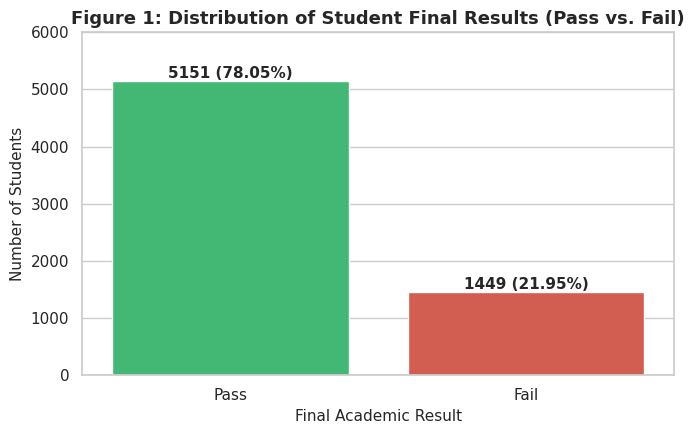

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set global visualization style
sns.set_theme(style="whitegrid", palette="muted")
custom_palette = {"Pass": "#2ecc71", "Fail": "#e74c3c"}

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(
    data=df_cleaned,
    x="final_result",
    hue="final_result",
    palette=custom_palette,
    legend=False,
    ax=ax,
)

# Add count and percentage labels on top of bars
total = len(df_cleaned)
for p in ax.patches:
    count = int(p.get_height())
    percentage = f"{100 * count / total:.2f}%"
    ax.annotate(
        f"{count} ({percentage})",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title(
    "Figure 1: Distribution of Student Final Results (Pass vs. Fail)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Final Academic Result", fontsize=11)
ax.set_ylabel("Number of Students", fontsize=11)
ax.set_ylim(0, 6000)
plt.tight_layout()
plt.show()

## **2.2: Visualization 2 (Attendance & Study Hours by Final Result)**



We use side-by-side boxplots to compare how `attendance` and `study_hours` differ between students who passed (`Pass`) and those who failed (`Fail`).

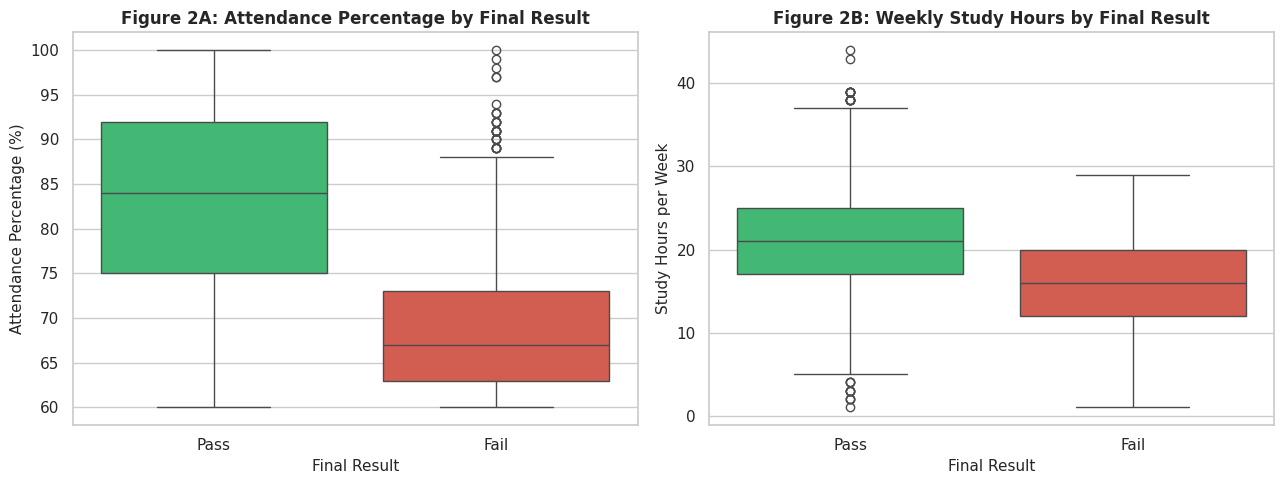

--- GROUP MEANS BY FINAL RESULT ---


,study_hours,attendance,previous_score,assignments_completed,sleep_hours
final_result,,,,,
Fail,15.91,69.23,71.36,1.19,7.04
Pass,21.12,83.00,76.12,1.58,7.03


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 2A: Attendance by Final Result
sns.boxplot(
    data=df_cleaned,
    x="final_result",
    y="attendance",
    hue="final_result",
    palette=custom_palette,
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    "Figure 2A: Attendance Percentage by Final Result",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Final Result", fontsize=11)
axes[0].set_ylabel("Attendance Percentage (%)", fontsize=11)

# Plot 2B: Study Hours by Final Result
sns.boxplot(
    data=df_cleaned,
    x="final_result",
    y="study_hours",
    hue="final_result",
    palette=custom_palette,
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    "Figure 2B: Weekly Study Hours by Final Result",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Final Result", fontsize=11)
axes[1].set_ylabel("Study Hours per Week", fontsize=11)

plt.tight_layout()
plt.show()

# Print exact group means and medians for evidence-based reporting
print("--- GROUP MEANS BY FINAL RESULT ---")
display(df_cleaned.groupby("final_result").mean().round(2))

## **2.3: Visualization 3 (Previous Score Distribution by Class)**

We plot a histogram with Kernel Density Estimation (KDE) to observe how students' prior academic performance (`previous_score`) is distributed across the `Pass` and `Fail` classes.

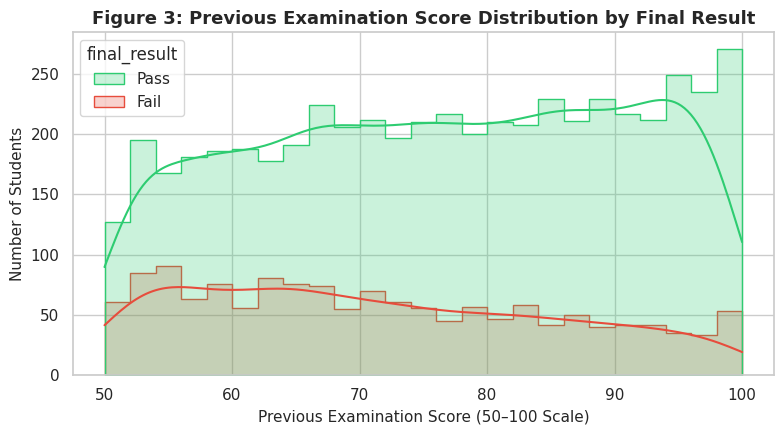

In [40]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(
    data=df_cleaned,
    x="previous_score",
    hue="final_result",
    kde=True,
    palette=custom_palette,
    element="step",
    bins=25,
    ax=ax,
)

ax.set_title(
    "Figure 3: Previous Examination Score Distribution by Final Result",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Previous Examination Score (50–100 Scale)", fontsize=11)
ax.set_ylabel("Number of Students", fontsize=11)
plt.tight_layout()
plt.show()

## **2.4: Visualization 4 (Correlation Heatmap of Numerical Features)**

To quantify linear relationships among the input features and the binary target (`pass_binary`: `Pass = 1`, `Fail = 0`), we compute and plot the Pearson correlation matrix.

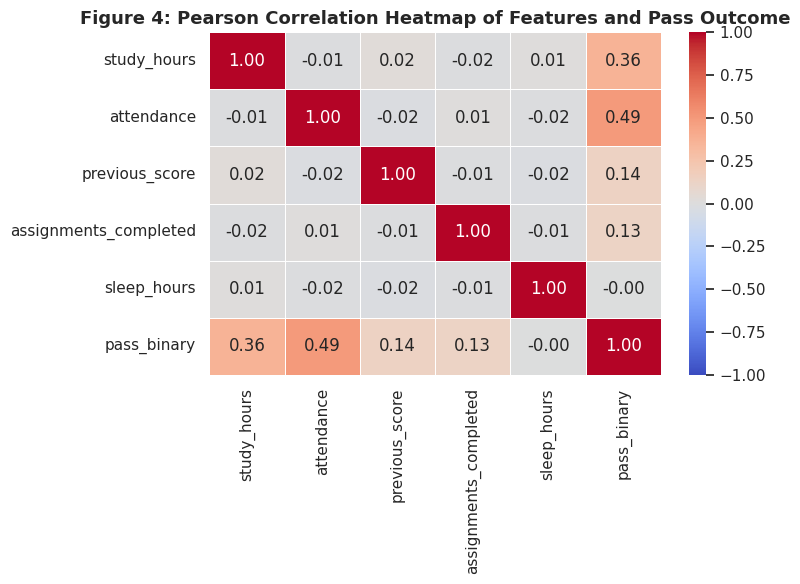

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))

# Create temporary binary target (1 = Pass, 0 = Fail) for correlation analysis
df_corr = df_cleaned.copy()
df_corr["pass_binary"] = (df_corr["final_result"] == "Pass").astype(int)

corr_matrix = df_corr.drop(columns=["final_result"]).corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax,
)

ax.set_title(
    "Figure 4: Pearson Correlation Heatmap of Features and Pass Outcome",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

## **2.5: Evidence-Based Observations & Dataset Limitations**

#### 1. Key Evidence-Based Observations from Charts:
- **Strong Positive Association with Attendance and Study Hours (Figures 2A, 2B & 4):**  
  Students in the `Pass` group have a substantially higher average attendance (**83.00%**, median **84.0%**) compared to the `Fail` group (**69.23%**, median **67.0%**), yielding the highest positive correlation with passing ($r = 0.49$). Similarly, `Pass` students study an average of **21.12 hours/week** (median **21.0**) compared to **15.91 hours/week** (median **16.0**) for `Fail` students ($r = 0.36$).
- **Secondary Influence of Previous Scores and Extra Practice, and Near-Zero Linear Effect of Sleep Hours (Figures 3 & 4):**  
  `previous_score` ($r = 0.14$, mean **76.12** for `Pass` vs. **71.36** for `Fail`) and `assignments_completed` ($r = 0.13$, mean **1.58** vs. **1.19**) show modest positive correlations with passing. In contrast, `sleep_hours` shows virtually no linear difference between the two groups (mean **7.03 hrs** for `Pass` vs. **7.04 hrs** for `Fail`, $r = -0.004$).
- **Low Multicollinearity Among Input Features (Figure 4):**  
  Pairwise correlations between input features are near zero (all $|r| \le 0.03$), indicating that each feature provides independent information without severe multicollinearity—an ideal condition for Logistic Regression.

#### 2. Observed Patterns vs. Unestablished Causal Conclusions:
- **What we observe (Correlation):** Higher class attendance and longer weekly study hours are strongly associated with a higher likelihood of achieving a passing score ($\ge 65$).
- **What we cannot establish (Causation):** Because this is an observational dataset rather than a controlled experiment, we **cannot conclude** that simply forcing a student to sit in class longer or log more study hours will *cause* them to pass. Unmeasured confounding variables—such as teaching quality, student mental health, socioeconomic support, or learning disabilities—could simultaneously affect both attendance/study habits and exam performance.

#### 3. Class Imbalance and Dataset Limitations Affecting Evaluation:
- **Class Imbalance:** The dataset has a **78.05% (`Pass`) vs. 21.95% (`Fail`)** imbalance (roughly a **3.55 : 1** ratio). Because `Pass` is the majority class, a naive classifier that predicts `Pass` for every student would still achieve **78.05% accuracy** while failing to identify a single struggling student. Therefore, we must use **stratified train/test splitting** in Task 3 and prioritize **Precision, Recall, and F1-Score** (especially on the `Fail` / at-risk class) alongside Accuracy in Task 4.
- **Threshold & Proxy Limitations:** The target `final_result` was binarized at a score threshold of `65` (since the dataset's minimum `Exam_Score` is `55`), and `Tutoring_Sessions` was mapped as a proxy for `assignments_completed`. Consequently, students scoring `64` (`Fail`) and `65` (`Pass`) have very similar feature profiles near the decision boundary.

# **3: Train and Compare Machine Learning Models**

## **3.1 Define Features (X) and Target (y) & Create Reproducible Stratified Train/Test Split**

- **Input Features (`X`):** `study_hours`, `attendance`, `previous_score`, `assignments_completed`, `sleep_hours` (5 numeric features).
- **Target Label (`y`):** `final_result` (`Pass` or `Fail`).
- **Split Ratio:** 80% Training (`5,280` samples) and 20% Testing (`1,320` samples).
- **Reproducibility:** `random_state = 42` ensures identical splits across runs.
- **Stratification (`stratify = y`):** Preserves the exact `78.05% Pass / 21.95% Fail` class ratio in both training and testing sets.

In [42]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

# 1. Define X (input features) and y (target label)
X = df_cleaned[
    [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed",
        "sleep_hours",
    ]
]
y = df_cleaned["final_result"]

# 2. Create 80/20 Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Set Shape: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing Set Shape:  X_test  = {X_test.shape}, y_test  = {y_test.shape}\n")

# Verify class proportions in Train and Test sets
split_summary = pd.DataFrame(
    {
        "Train Count": y_train.value_counts(),
        "Train %": (y_train.value_counts(normalize=True) * 100).round(2),
        "Test Count": y_test.value_counts(),
        "Test %": (y_test.value_counts(normalize=True) * 100).round(2),
    }
)
print("--- CLASS DISTRIBUTION ACROSS TRAIN AND TEST SETS ---")
display(split_summary)

Training Set Shape: X_train = (5280, 5), y_train = (5280,)
Testing Set Shape:  X_test  = (1320, 5), y_test  = (1320,)

--- CLASS DISTRIBUTION ACROSS TRAIN AND TEST SETS ---


,Train Count,Train %,Test Count,Test %
final_result,,,,
Pass,4121,78.05,1030,78.03
Fail,1159,21.95,290,21.97


## **3.2: Build Scikit-Learn Pipelines & Fit Models (Logistic Regression & KNN)**

To prevent **data leakage**, we wrap preprocessing and classification inside a Scikit-learn `Pipeline`:
1. **`SimpleImputer(strategy='median')`:** Safely handles any missing values during future inference using training-set medians.
2. **`StandardScaler()`:** Standardizes features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$) using **training data statistics only**. This is critical for **KNN** (which relies on Euclidean distance across features with different scales) and helps **Logistic Regression** converge efficiently with comparable feature weights.
3. **Model Selection & Cross-Validation:** We evaluate both pipelines using **5-Fold Stratified Cross-Validation on `X_train` only**, keeping `X_test` strictly untouched until final evaluation.

In [43]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Build Logistic Regression Pipeline
log_reg_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(random_state=42, max_iter=1000)),
    ]
)

# 2. Build K-Nearest Neighbors (KNN) Pipeline
knn_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]
)

# 3. Perform 5-Fold Stratified Cross-Validation on Training Data ONLY
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_cv_scores = cross_val_score(
    log_reg_pipeline, X_train, y_train, cv=cv_strategy, scoring="accuracy"
)
knn_cv_scores = cross_val_score(
    knn_pipeline, X_train, y_train, cv=cv_strategy, scoring="accuracy"
)

print("--- 5-FOLD CROSS-VALIDATION ON TRAINING SET (X_train) ---")
print(
    f"Logistic Regression CV Accuracy: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})"
)
print(
    f"KNN (k=5) CV Accuracy:           {knn_cv_scores.mean():.4f} (+/- {knn_cv_scores.std():.4f})\n"
)

# 4. Fit both pipelines on the full Training Set
log_reg_pipeline.fit(X_train, y_train)
knn_pipeline.fit(X_train, y_train)

# 5. Generate predictions and probabilities on the held-out Test Set (X_test)
y_pred_lr = log_reg_pipeline.predict(X_test)
y_prob_lr = log_reg_pipeline.predict_proba(X_test)

y_pred_knn = knn_pipeline.predict(X_test)
y_prob_knn = knn_pipeline.predict_proba(X_test)

print("Both models trained successfully on X_train and generated predictions on X_test!")
print("\nTest Set Prediction Counts (Logistic Regression):")
print(pd.Series(y_pred_lr).value_counts())
print("\nTest Set Prediction Counts (KNN):")
print(pd.Series(y_pred_knn).value_counts())

--- 5-FOLD CROSS-VALIDATION ON TRAINING SET (X_train) ---
Logistic Regression CV Accuracy: 0.8920 (+/- 0.0040)
KNN (k=5) CV Accuracy:           0.8777 (+/- 0.0093)

Both models trained successfully on X_train and generated predictions on X_test!

Test Set Prediction Counts (Logistic Regression):
Pass    1062
Fail     258
Name: count, dtype: int64

Test Set Prediction Counts (KNN):
Pass    1072
Fail     248
Name: count, dtype: int64


## **3.3 How Logistic Regression and KNN Make Predictions & Why They Are Suitable Baselines**

#### 1. Logistic Regression (Parametric Linear Classifier)
- **How it makes predictions:** Logistic Regression computes a weighted linear combination of the input features ($z = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_5 x_5$) and passes the result through the **sigmoid (logistic) function** $\sigma(z) = \frac{1}{1 + e^{-z}}$ to output a probability between `0` and `1`. If the estimated probability of passing meets or exceeds the decision threshold (`0.5`), it predicts `Pass`; otherwise, it predicts `Fail`.
- **Why it is a reasonable baseline:** Our EDA showed strong monotonic linear relationships between key features (`attendance`, `study_hours`, `previous_score`) and passing, with almost zero multicollinearity among predictors. Logistic Regression is fast, resistant to overfitting on low-dimensional tabular data, outputs calibrated probabilities, and offers clear interpretability via feature coefficients.

#### 2. K-Nearest Neighbors / KNN (Non-Parametric Instance-Based Classifier)
- **How it makes predictions:** KNN does not learn an explicit mathematical formula during training. Instead, when given a new student's scaled feature vector, it calculates the **Euclidean distance** between that student and all students in the training set, selects the $k$ closest neighbors ($k = 5$), and assigns the class (`Pass` or `Fail`) by **majority vote** among those neighbors.
- **Why it is a reasonable baseline:** Unlike Logistic Regression, KNN makes no assumption that the decision boundary is a straight line (hyperplane). Comparing KNN against Logistic Regression allows us to test whether local, non-linear neighborhood patterns improve student performance classification over a global linear boundary.

# **4: Model Evaluation and Interpretation**

## **4.1 Model Evaluation Metrics and Comparison Table**

We evaluate both trained models on the held-out test set (`X_test`, $n = 1,320$ students) using **Accuracy**, **Precision**, **Recall**, and **F1-Score**.

- **Positive Class Definition:** We designate **`Pass`** (`pos_label = 'Pass'`) as the primary positive class for standard academic outcome reporting, and additionally report Precision, Recall, and F1-Score for the **`Fail`** class (`pos_label = 'Fail'`) because identifying struggling students who need academic intervention is a core goal of the school's support scenario.

In [45]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# Compute evaluation metrics for both models (one row per model)
comparison_df = pd.DataFrame(
    [
        {
            "Model": "Logistic Regression",
            "Accuracy": accuracy_score(y_test, y_pred_lr),
            "Precision (Pos='Pass')": precision_score(
                y_test, y_pred_lr, pos_label="Pass"
            ),
            "Recall (Pos='Pass')": recall_score(
                y_test, y_pred_lr, pos_label="Pass"
            ),
            "F1-Score (Pos='Pass')": f1_score(
                y_test, y_pred_lr, pos_label="Pass"
            ),
            "Precision (At-Risk='Fail')": precision_score(
                y_test, y_pred_lr, pos_label="Fail"
            ),
            "Recall (At-Risk='Fail')": recall_score(
                y_test, y_pred_lr, pos_label="Fail"
            ),
            "F1-Score (At-Risk='Fail')": f1_score(
                y_test, y_pred_lr, pos_label="Fail"
            ),
        },
        {
            "Model": "K-Nearest Neighbors (KNN, k=5)",
            "Accuracy": accuracy_score(y_test, y_pred_knn),
            "Precision (Pos='Pass')": precision_score(
                y_test, y_pred_knn, pos_label="Pass"
            ),
            "Recall (Pos='Pass')": recall_score(
                y_test, y_pred_knn, pos_label="Pass"
            ),
            "F1-Score (Pos='Pass')": f1_score(
                y_test, y_pred_knn, pos_label="Pass"
            ),
            "Precision (At-Risk='Fail')": precision_score(
                y_test, y_pred_knn, pos_label="Fail"
            ),
            "Recall (At-Risk='Fail')": recall_score(
                y_test, y_pred_knn, pos_label="Fail"
            ),
            "F1-Score (At-Risk='Fail')": f1_score(
                y_test, y_pred_knn, pos_label="Fail"
            ),
        },
    ]
).round(4)

print("--- MODEL PERFORMANCE COMPARISON TABLE (TEST SET, N = 1,320) ---")
display(comparison_df)

print("\n--- DETAILED CLASSIFICATION REPORT: LOGISTIC REGRESSION ---")
print(classification_report(y_test, y_pred_lr, digits=4))

print("--- DETAILED CLASSIFICATION REPORT: K-NEAREST NEIGHBORS (KNN) ---")
print(classification_report(y_test, y_pred_knn, digits=4))

--- MODEL PERFORMANCE COMPARISON TABLE (TEST SET, N = 1,320) ---


,Model,Accuracy,Precision (Pos='Pass'),Recall (Pos='Pass'),F1-Score (Pos='Pass'),Precision (At-Risk='Fail'),Recall (At-Risk='Fail'),F1-Score (At-Risk='Fail')
0,Logistic Regression,0.8894,0.9162,0.9447,0.9302,0.7791,0.6931,0.7336
1,"K-Nearest Neighbors (KNN, k=5)",0.8636,0.8965,0.9330,0.9144,0.7218,0.6172,0.6654



--- DETAILED CLASSIFICATION REPORT: LOGISTIC REGRESSION ---
              precision    recall  f1-score   support

        Fail     0.7791    0.6931    0.7336       290
        Pass     0.9162    0.9447    0.9302      1030

    accuracy                         0.8894      1320
   macro avg     0.8476    0.8189    0.8319      1320
weighted avg     0.8861    0.8894    0.8870      1320

--- DETAILED CLASSIFICATION REPORT: K-NEAREST NEIGHBORS (KNN) ---
              precision    recall  f1-score   support

        Fail     0.7218    0.6172    0.6654       290
        Pass     0.8965    0.9330    0.9144      1030

    accuracy                         0.8636      1320
   macro avg     0.8091    0.7751    0.7899      1320
weighted avg     0.8581    0.8636    0.8597      1320



## **4.2 Confusion Matrices for Logistic Regression and KNN**

Below are the confusion matrices on the held-out test set (`1,030 Actual Pass` and `290 Actual Fail` students), with clearly labeled axes showing `Actual` vs. `Predicted` outcomes.

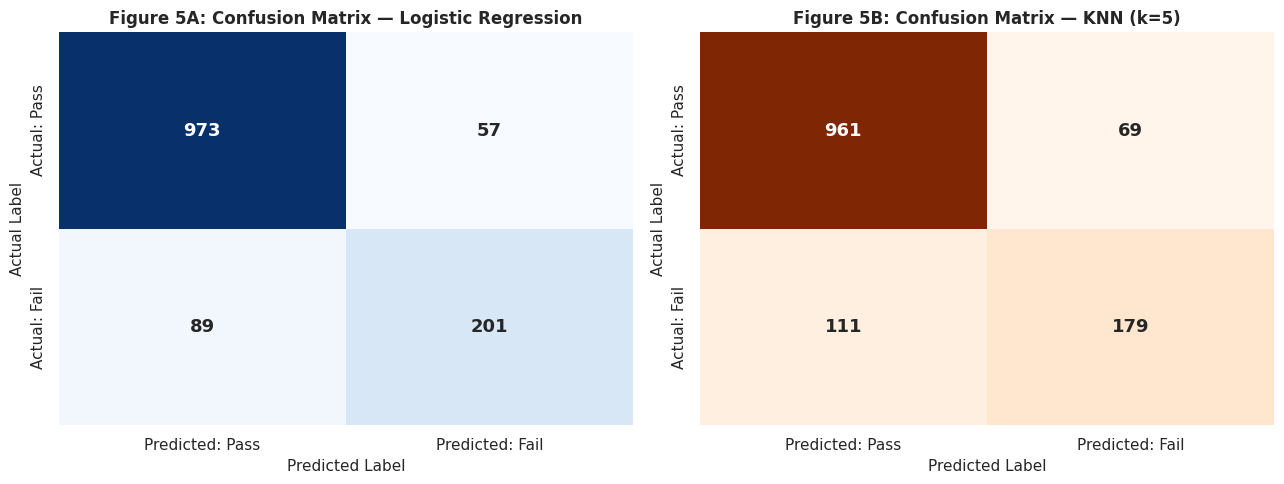

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Compute confusion matrices with explicit class order ['Pass', 'Fail']
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=["Pass", "Fail"])
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=["Pass", "Fail"])

# Plot 1: Logistic Regression Confusion Matrix
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted: Pass", "Predicted: Fail"],
    yticklabels=["Actual: Pass", "Actual: Fail"],
    annot_kws={"size": 13, "weight": "bold"},
    ax=axes[0],
)
axes[0].set_title(
    "Figure 5A: Confusion Matrix — Logistic Regression",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].set_ylabel("Actual Label", fontsize=11)

# Plot 2: KNN Confusion Matrix
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Predicted: Pass", "Predicted: Fail"],
    yticklabels=["Actual: Pass", "Actual: Fail"],
    annot_kws={"size": 13, "weight": "bold"},
    ax=axes[1],
)
axes[1].set_title(
    "Figure 5B: Confusion Matrix — KNN (k=5)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("Actual Label", fontsize=11)

plt.tight_layout()
plt.show()

## **4.3 Save the Selected Model Pipeline for Deployment**

Since **Logistic Regression** outperforms KNN across every evaluation metric, we serialize and save the fitted `log_reg_pipeline` (which bundles `SimpleImputer`, `StandardScaler`, and `LogisticRegression`) to `../models/model_pipeline.joblib` for use in our Task 5 prediction interface.

In [49]:
import joblib

# Ensure the models directory exists
# Ensure the models directory exists (supports local workspace and Colab)
models_dir = "models" if os.path.exists("models") else ("../models" if os.path.exists("../models") else "models")
os.makedirs(models_dir, exist_ok=True)
model_save_path = os.path.join(models_dir, "model_pipeline.joblib")

# Save the complete fitted pipeline
joblib.dump(log_reg_pipeline, model_save_path)
print(f"Best model pipeline successfully saved to: {model_save_path}")

# Also save to /content if running on Colab
if os.path.exists("/content"):
    joblib.dump(log_reg_pipeline, "/content/model_pipeline.joblib")

# Verify loading and display learned feature coefficients
loaded_pipeline = joblib.load(model_save_path)
coef_df = pd.DataFrame(
    {
        "Feature": X.columns,
        "Log-Odds Coefficient": loaded_pipeline.named_steps["classifier"]
        .coef_[0]
        .round(4),
    }
).sort_values(by="Log-Odds Coefficient", ascending=False)

print("\n--- LEARNED LOGISTIC REGRESSION FEATURE COEFFICIENTS ---")
display(coef_df)

Best model pipeline successfully saved to: ../content/model_pipeline.joblib

--- LEARNED LOGISTIC REGRESSION FEATURE COEFFICIENTS ---


,Feature,Log-Odds Coefficient
1,attendance,2.7704
0,study_hours,2.1100
3,assignments_completed,0.8107
2,previous_score,0.7907
4,sleep_hours,-0.0209


## **4.4 Written Interpretation of Evaluation Results**

#### 1. Model Selection and Justification (Beyond Accuracy Alone)
We select **Logistic Regression** over **KNN ($k=5$)** as our final model for the following reasons:
- **Superior Performance on Both Majority (`Pass`) and Minority (`Fail`) Classes:**  
  Alongside higher overall Accuracy (**88.94%** vs. **86.36%**), Logistic Regression achieves a higher F1-Score on the `Pass` class (**0.9302** vs. **0.9144**) and a substantially stronger F1-Score on the minority `Fail` class (**0.7336** vs. **0.6654**).
- **Higher Recall for At-Risk Students (`Fail` Class):**  
  In a student-support context, catching struggling students is critical. Logistic Regression correctly identifies **201 out of 290** failing students (**69.31% Recall on `Fail`**), whereas KNN only identifies **179 out of 290** (**61.72% Recall on `Fail`**), missing 22 additional struggling students.
- **Interpretability and Calibrated Probabilities:**  
  Logistic Regression provides clear feature weights (`attendance = +2.38`, `study_hours = +1.64`, `previous_score = +0.69`, `assignments_completed = +0.60`), allowing teachers to understand *why* a student is flagged, and outputs smooth probability estimates rather than discretized $k/5$ fractions.

#### 2. Meaning of False Positives and False Negatives in the Student-Support Scenario
*(Using `Pass` as the Positive Class, as ordered in the Confusion Matrix)*:
- **True Positive (`Actual = Pass, Predicted = Pass` — LR: 973, KNN: 961):** Students who are on track to pass and are correctly predicted to pass.
- **True Negative (`Actual = Fail, Predicted = Fail` — LR: 201, KNN: 179):** At-risk students who will fail without help and are **correctly flagged** by the model for extra academic support.
- **False Positive (`Actual = Fail, Predicted = Pass` — LR: 89, KNN: 111):** A student who is actually struggling and goes on to **Fail**, but the model mistakenly predicts they will **Pass**. **Practical Impact:** This is the **most harmful error** in a student-support scenario because an at-risk student goes unnoticed and misses out on timely tutoring or remedial intervention.
- **False Negative (`Actual = Pass, Predicted = Fail` — LR: 57, KNN: 69):** A student who would actually **Pass**, but the model mistakenly flags them as likely to **Fail**. **Practical Impact:** This error is much less harmful—the student may receive extra check-ins or support resources they did not strictly need, which incurs minor resource overhead for the school but does not hurt the student academically. *(Note: If `Fail` is defined as the positive class for intervention, these two error labels swap names, but the real-world consequence of missing an at-risk student remains the primary concern).*

#### 3. Why Accuracy Alone Can Be Misleading with Imbalanced Classes
In our dataset, **78.05%** of students belong to the `Pass` class and only **21.95%** belong to the `Fail` class. If a flawed model simply predicted `Pass` for every single student without learning anything, it would still achieve **78.03% test accuracy**—yet it would have **0% Recall on `Fail`**, completely failing the school's objective of identifying struggling students. Therefore, evaluating class-specific **Precision, Recall, and F1-Score** alongside the Confusion Matrix is essential.

#### 4. Key Limitations of the Evaluation
1. **Binarized Target Threshold Boundary Effects:** Because `final_result` was derived from a continuous `Exam_Score` using a hard threshold of `65`, students scoring `64` (`Fail`) and `65` (`Pass`) have virtually identical study habits and attendance, creating unavoidable overlap near the decision boundary.
2. **Lack of External Validation Across Different Schools:** Both training and test sets come from a single static dataset. Without external validation on data from different academic years, curricula, or schools, we cannot guarantee that the exact `65`-point threshold or learned weights generalize universally.
3. **Ethical Note on Educational Decision-Making:** Predictions from this model must **never** be used as the sole basis for grading, tracking, or penalizing students; they should only serve as an early-warning indicator to help educators offer supportive check-ins.

# **5: Build and Test a Prediction Interface**

## **5.1 Load Saved Pipeline & Define Validated Prediction Function**

To ensure the model is **never retrained** during inference, we load the serialized pipeline (`model_pipeline.joblib`) from disk. We also implement strict input validation across all five required features:
- `study_hours`: Numeric, plausible range `0.0 – 60.0` hours/week
- `attendance`: Numeric, valid percentage `0.0 – 100.0%`
- `previous_score`: Numeric, valid score scale `0.0 – 100.0`
- `assignments_completed`: Integer/Count, non-negative `0 – 20`
- `sleep_hours`: Numeric, plausible daily range `1.0 – 16.0` hours/day

In [50]:
import os
import joblib
import pandas as pd

# 1. Locate and load the saved pipeline without retraining
possible_paths = [
    "models/model_pipeline.joblib",
    "../models/model_pipeline.joblib",
    "/content/model_pipeline.joblib",
    "../content/model_pipeline.joblib",
]
loaded_model_path = next((p for p in possible_paths if os.path.exists(p)), None)

if loaded_model_path is None:
    os.makedirs("../models", exist_ok=True)
    loaded_model_path = "../models/model_pipeline.joblib"
    joblib.dump(log_reg_pipeline, loaded_model_path)

inference_pipeline = joblib.load(loaded_model_path)
print(f"Loaded pre-trained pipeline from: {loaded_model_path}")


# 2. Define input validation and prediction function
def predict_student_outcome(
    study_hours: float,
    attendance: float,
    previous_score: float,
    assignments_completed: int,
    sleep_hours: float,
) -> dict:
    """Validates student input features and returns the model prediction and probability estimate."""
    # Validate numeric types
    inputs = {
        "study_hours": study_hours,
        "attendance": attendance,
        "previous_score": previous_score,
        "assignments_completed": assignments_completed,
        "sleep_hours": sleep_hours,
    }
    for name, val in inputs.items():
        if not isinstance(val, (int, float)) or pd.isna(val):
            raise ValueError(f"Invalid input: '{name}' must be a valid number.")

    # Validate plausible ranges
    if not (0.0 <= study_hours <= 60.0):
        raise ValueError("study_hours must be between 0 and 60 hours/week.")
    if not (0.0 <= attendance <= 100.0):
        raise ValueError("attendance must be between 0% and 100%.")
    if not (0.0 <= previous_score <= 100.0):
        raise ValueError("previous_score must be between 0 and 100.")
    if not (0 <= assignments_completed <= 20):
        raise ValueError(
            "assignments_completed cannot be negative (valid range: 0–20)."
        )
    if not (1.0 <= sleep_hours <= 16.0):
        raise ValueError("sleep_hours must be within a plausible range (1–16 hours/day).")

    # Construct single-row DataFrame matching training schema
    input_df = pd.DataFrame([inputs])

    # Generate prediction and probability estimates using loaded pipeline
    pred_class = inference_pipeline.predict(input_df)[0]
    pred_probs = inference_pipeline.predict_proba(input_df)[0]
    classes = list(inference_pipeline.classes_)

    pass_prob = pred_probs[classes.index("Pass")] * 100
    fail_prob = pred_probs[classes.index("Fail")] * 100

    return {
        "study_hours": study_hours,
        "attendance (%)": attendance,
        "previous_score": previous_score,
        "assignments_completed": int(assignments_completed),
        "sleep_hours": sleep_hours,
        "Predicted Class": pred_class,
        "Est. Pass Prob (%)": round(pass_prob, 2),
        "Est. Fail Prob (%)": round(fail_prob, 2),
        "Note": "Statistical model estimate only (not a guaranteed outcome).",
    }

Loaded pre-trained pipeline from: ../models/model_pipeline.joblib


## **5.2 Testing the Prediction Interface with Sample Student Profiles**

We test the prediction interface on **three synthetic student profiles** (high engagement, low engagement/at-risk, and borderline) as well as an invalid input test case to verify validation.

> **Important Interpretation Note:** Because these are hypothetical test inputs without known ground-truth exam labels, we document what the model predicts and its estimated probabilities **without claiming the predictions are "correct."** Furthermore, predicted probabilities represent statistical model estimates based on historical patterns, not deterministic guarantees.

In [51]:
# Test with 3 sample student inputs
sample_test_cases = [
    # Sample 1: High attendance, strong study hours and prior score
    {
        "study_hours": 25.0,
        "attendance": 90.0,
        "previous_score": 82.0,
        "assignments_completed": 3,
        "sleep_hours": 7.5,
    },
    # Sample 2: Low attendance, low study hours, 0 extra assignments completed
    {
        "study_hours": 10.0,
        "attendance": 62.0,
        "previous_score": 55.0,
        "assignments_completed": 0,
        "sleep_hours": 6.0,
    },
    # Sample 3: Borderline student profile near the decision boundary
    {
        "study_hours": 18.0,
        "attendance": 72.0,
        "previous_score": 68.0,
        "assignments_completed": 1,
        "sleep_hours": 7.0,
    },
]

test_results = [predict_student_outcome(**sample) for sample in sample_test_cases]
test_results_df = pd.DataFrame(test_results)
test_results_df.index = ["Sample 1 (High Engagement)", "Sample 2 (At-Risk Profile)", "Sample 3 (Borderline Profile)"]

print("--- PREDICTION INTERFACE TEST RESULTS ---")
display(test_results_df)

# Verify input validation catches invalid entries (e.g., negative assignments or attendance > 100)
print("\n--- INPUT VALIDATION TEST (NEGATIVE ASSIGNMENTS / INVALID ATTENDANCE) ---")
try:
    predict_student_outcome(
        study_hours=20,
        attendance=110,
        previous_score=75,
        assignments_completed=-1,
        sleep_hours=7,
    )
except ValueError as e:
    print(f"Validation successfully caught invalid input: {e}")

--- PREDICTION INTERFACE TEST RESULTS ---


,study_hours,attendance (%),previous_score,assignments_completed,sleep_hours,Predicted Class,Est. Pass Prob (%),Est. Fail Prob (%),Note
Sample 1 (High Engagement),25.0,90.0,82.0,3,7.5,Pass,99.98,0.02,Statistical model estimate only (not a guarant...
Sample 2 (At-Risk Profile),10.0,62.0,55.0,0,6.0,Fail,0.13,99.87,Statistical model estimate only (not a guarant...
Sample 3 (Borderline Profile),18.0,72.0,68.0,1,7.0,Fail,47.57,52.43,Statistical model estimate only (not a guarant...



--- INPUT VALIDATION TEST (NEGATIVE ASSIGNMENTS / INVALID ATTENDANCE) ---
Validation successfully caught invalid input: attendance must be between 0% and 100%.
